# SLAM: closing a pose-graph loop

**Notebook author: Ziad Mosalam**  
Companion to *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems* by Khalid M. Mosalam.

A robot returns to its starting place, but accumulated odometry says it has not. A loop-closure observation couples the last pose to the first. The resulting correction is distributed through the trajectory according to the uncertainty assigned to each observation.

This notebook implements the **pose-graph back end** of SLAM. The route and all measurements are simulated. The loop correspondence is supplied, so feature detection, association, and rejection of false closures are outside this example. No field dataset is used.

Run the cells from top to bottom. The final figure is displayed here and exported to `../figures/slam-loop-closure.pdf` and `.png`. Dependencies are NumPy, SciPy, and Matplotlib.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix

plt.style.use('book.mplstyle')
BLUE, GOLD, TEAL, INK = '#003262', '#B17A00', '#247C86', '#30363B'
figure_dir = Path('../figures')
figure_dir.mkdir(exist_ok=True)
rng = np.random.default_rng(7)

## 1. Poses and relative measurements

A planar pose is $\mathbf{x}_i=(p_{x,i},p_{y,i},\theta_i)$. Positions are in metres and headings are in radians. A relative measurement from pose $i$ to pose $j$ is expressed in the **local frame of pose $i$**:

$$
 h_{ij}(\mathbf{x}_i,\mathbf{x}_j)=
 \begin{bmatrix}
 R(\theta_i)^\mathsf{T}(\mathbf{p}_j-\mathbf{p}_i)\\
 \operatorname{wrap}(\theta_j-\theta_i)
 \end{bmatrix},\qquad
 R(\theta)=\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix}.
$$

`wrap_angle` chooses the equivalent angle in $[-\pi,\pi)$. The angular *residual* must also be wrapped. Otherwise a change across $\pi$ can look like an erroneous full revolution.

In [2]:
def wrap_angle(angle):
    return (angle + np.pi) % (2 * np.pi) - np.pi


def relative_pose(a, b):
    c, s = np.cos(a[2]), np.sin(a[2])
    local_translation = np.array([[c, s], [-s, c]]) @ (b[:2] - a[:2])
    return np.r_[local_translation, wrap_angle(b[2] - a[2])]


def compose_pose(pose, increment):
    c, s = np.cos(pose[2]), np.sin(pose[2])
    position = pose[:2] + np.array([[c, -s], [s, c]]) @ increment[:2]
    return np.r_[position, wrap_angle(pose[2] + increment[2])]

## 2. One synthetic circuit

The robot follows an elliptical route with 81 poses, including the repeated starting location. Each adjacent-pose measurement has independent Gaussian noise with standard deviations $(0.06\,\mathrm{m},0.06\,\mathrm{m},1.2^\circ)$. The independent final-to-first loop measurement has standard deviations $(0.08\,\mathrm{m},0.08\,\mathrm{m},1.0^\circ)$.

These are explicit teaching parameters, not calibrated sensor specifications. Translation errors are modelled in the measuring pose's local frame. The diagonal covariance assumption neglects correlations between translation and rotation.

In [3]:
n_poses = 81
phase = np.linspace(0, 2 * np.pi, n_poses)
truth = np.column_stack((
    9 * np.sin(phase),
    6 * (1 - np.cos(phase)),
    np.arctan2(6 * np.sin(phase), 9 * np.cos(phase)),
))
true_increments = np.array([
    relative_pose(a, b) for a, b in zip(truth[:-1], truth[1:])
])

odometry_std = np.array([0.06, 0.06, np.deg2rad(1.2)])
closure_std = np.array([0.08, 0.08, np.deg2rad(1.0)])
odometry = true_increments + rng.normal(size=true_increments.shape) * odometry_std
odometry[:, 2] = wrap_angle(odometry[:, 2])
closure = relative_pose(truth[-1], truth[0]) + rng.normal(size=3) * closure_std
closure[2] = wrap_angle(closure[2])

# The first pose defines the coordinate frame; it is not an estimated variable.
anchor = np.array([0.0, 0.0, 0.0])
dead_reckoning = [anchor.copy()]
for measurement in odometry:
    dead_reckoning.append(compose_pose(dead_reckoning[-1], measurement))
dead_reckoning = np.asarray(dead_reckoning)

# Each row identifies the two poses joined by a measured relative transform.
edges = np.column_stack((np.arange(n_poses - 1), np.arange(1, n_poses)))
edges = np.vstack((edges, [n_poses - 1, 0]))
measurements = np.vstack((odometry, closure))
standard_deviations = np.vstack((
    np.tile(odometry_std, (n_poses - 1, 1)), closure_std,
))

## 3. A weighted pose-graph objective

For each edge, subtract its measurement from the predicted relative pose, wrap the angular component, and divide each component by its measurement standard deviation. The estimate minimizes

$$
 \frac12\sum_{(i,j)\in\mathcal E}
 \left\|\Sigma_{ij}^{-1/2}
 \begin{bmatrix}
 [h_{ij}]_{1:2}-[\mathbf z_{ij}]_{1:2}\\
 \operatorname{wrap}([h_{ij}]_3-[\mathbf z_{ij}]_3)
 \end{bmatrix}\right\|^2.
$$

This is the Gaussian least-squares objective for the stated local error model. With these small angular uncertainties, the principal wrapped angular residual gives the relevant local branch. No robust loss or outlier model is applied.

The first pose is held at $(0,0,0)$ to remove the arbitrary global translation and rotation. This fixes the **gauge**; it does not provide an absolute geographic location. All reported errors use that same initial-pose frame.

The Jacobian has only two pose blocks per edge. If $\mathbf q=R_i^\mathsf T(\mathbf p_j-\mathbf p_i)$ and $c=\cos\theta_i$, $s=\sin\theta_i$, the unwhitened blocks are

$$
 J_i=\begin{bmatrix}-c&-s&q_y\\s&-c&-q_x\\0&0&-1\end{bmatrix},\qquad
 J_j=\begin{bmatrix}c&s&0\\-s&c&0\\0&0&1\end{bmatrix}.
$$

Each row is then divided by the corresponding standard deviation. These derivatives apply away from the angular wrapping discontinuity.

In [4]:
def unpack(parameters):
    return np.vstack((anchor, parameters.reshape(-1, 3)))


def graph_residuals(parameters, observed, sigma):
    poses = unpack(parameters)
    a, b = poses[edges[:, 0]], poses[edges[:, 1]]
    delta = b[:, :2] - a[:, :2]
    c, s = np.cos(a[:, 2]), np.sin(a[:, 2])
    predicted = np.column_stack((
        c * delta[:, 0] + s * delta[:, 1],
        -s * delta[:, 0] + c * delta[:, 1],
        wrap_angle(b[:, 2] - a[:, 2]),
    ))
    residual = predicted - observed
    residual[:, 2] = wrap_angle(residual[:, 2])
    return (residual / sigma).ravel()


def graph_jacobian(parameters, observed, sigma):
    poses = unpack(parameters)
    jacobian = lil_matrix((3 * len(edges), len(parameters)))
    for edge_index, (i, j) in enumerate(edges):
        c, s = np.cos(poses[i, 2]), np.sin(poses[i, 2])
        qx, qy = relative_pose(poses[i], poses[j])[:2]
        Ji = np.array([[-c, -s, qy], [s, -c, -qx], [0, 0, -1]])
        Jj = np.array([[c, s, 0], [-s, c, 0], [0, 0, 1]])
        rows = slice(3 * edge_index, 3 * edge_index + 3)
        for pose_index, block in [(i, Ji), (j, Jj)]:
            if pose_index > 0:  # No columns belong to the fixed first pose.
                cols = slice(3 * (pose_index - 1), 3 * pose_index)
                jacobian[rows, cols] = block / sigma[edge_index, :, None]
    return jacobian.tocsr()

In [5]:
initial_parameters = dead_reckoning[1:].ravel()
fit = least_squares(
    graph_residuals, initial_parameters,
    jac=graph_jacobian,
    args=(measurements, standard_deviations),
    x_scale='jac',
    tr_options={'atol': 1e-12, 'btol': 1e-12},
    ftol=1e-10, xtol=1e-10, gtol=1e-10,
    max_nfev=200,
)
optimized = unpack(fit.x)
initial_residual = graph_residuals(initial_parameters, measurements, standard_deviations)
initial_cost = 0.5 * initial_residual @ initial_residual
print(f'Weighted objective: {initial_cost:.3f} -> {fit.cost:.3f}')
print(f'Solver: {fit.message}')

Weighted objective: 361.112 -> 1.646
Solver: `ftol` termination condition is satisfied.


## 4. Checks before interpreting the figure

The checks below test the coordinate conventions, reconstruction with exact measurements, the analytic Jacobian, and removal of the gauge freedoms. A falling objective confirms a better fit to the **measurements**. Improvement against the simulated truth is evaluated separately; the objective alone cannot guarantee it for an arbitrary noisy run.

In [6]:
# Exact local increments reconstruct the route in its fixed initial frame.
reconstructed = [anchor.copy()]
for increment in true_increments:
    reconstructed.append(compose_pose(reconstructed[-1], increment))
reconstructed = np.asarray(reconstructed)
np.testing.assert_allclose(reconstructed[:, :2], truth[:, :2], atol=1e-12)
np.testing.assert_allclose(wrap_angle(reconstructed[:, 2] - truth[:, 2]), 0, atol=1e-12)
np.testing.assert_allclose(wrap_angle((-np.pi + 0.01) - (np.pi - 0.01)), 0.02)

exact_measurements = np.vstack((true_increments, relative_pose(truth[-1], truth[0])))
np.testing.assert_allclose(
    graph_residuals(truth[1:].ravel(), exact_measurements, standard_deviations),
    0, atol=1e-12,
)

# Check the derivatives against a central finite difference in a separate direction.
direction = np.random.default_rng(19).normal(size=initial_parameters.size)
epsilon = 1e-6
finite_difference = (
    graph_residuals(initial_parameters + epsilon * direction, measurements, standard_deviations)
    - graph_residuals(initial_parameters - epsilon * direction, measurements, standard_deviations)
) / (2 * epsilon)
np.testing.assert_allclose(
    graph_jacobian(initial_parameters, measurements, standard_deviations) @ direction,
    finite_difference, rtol=1e-6, atol=1e-6,
)

np.testing.assert_allclose(initial_residual[:-3], 0, atol=1e-10)
assert fit.success and np.all(np.isfinite(fit.fun))
assert fit.cost < initial_cost
np.testing.assert_array_equal(optimized[0], anchor)
rank = np.linalg.matrix_rank(fit.jac.toarray())
assert rank == initial_parameters.size
print(f'Checks passed. Anchored Jacobian rank: {rank}/{initial_parameters.size}.')

Checks passed. Anchored Jacobian rank: 240/240.


In [7]:
position_error_before = np.linalg.norm(dead_reckoning[:, :2] - truth[:, :2], axis=1)
position_error_after = np.linalg.norm(optimized[:, :2] - truth[:, :2], axis=1)
heading_error_before = np.rad2deg(np.abs(wrap_angle(dead_reckoning[:, 2] - truth[:, 2])))
heading_error_after = np.rad2deg(np.abs(wrap_angle(optimized[:, 2] - truth[:, 2])))
distance = np.r_[0, np.cumsum(np.linalg.norm(np.diff(truth[:, :2], axis=0), axis=1))]
rmse_before = np.sqrt(np.mean(position_error_before**2))
rmse_after = np.sqrt(np.mean(position_error_after**2))
print(f'Position RMSE: {rmse_before:.3f} m before, {rmse_after:.3f} m after closure')
print(f'Final position error: {position_error_before[-1]:.3f} m before, '
      f'{position_error_after[-1]:.3f} m after closure')

Position RMSE: 1.867 m before, 0.700 m after closure
Final position error: 1.875 m before, 0.066 m after closure


## 5. What the loop changes

Panel (a) shows the chain of adjacent-pose constraints and the additional final-to-first loop edge. Dead reckoning satisfies the odometry chain exactly but disagrees with the loop measurement. Optimization balances all edges using their specified uncertainties.

Panels (b) and (d) compare the estimates with the known simulated route. The corrected loop does not force every intermediate pose onto the truth. A single loop adds limited information, and noisy local constraints still permit deformation between the endpoints. Panel (c) magnifies the final poses and the loop edge near the fixed starting pose. The plot shows one fixed-seed realization, not an average performance claim.

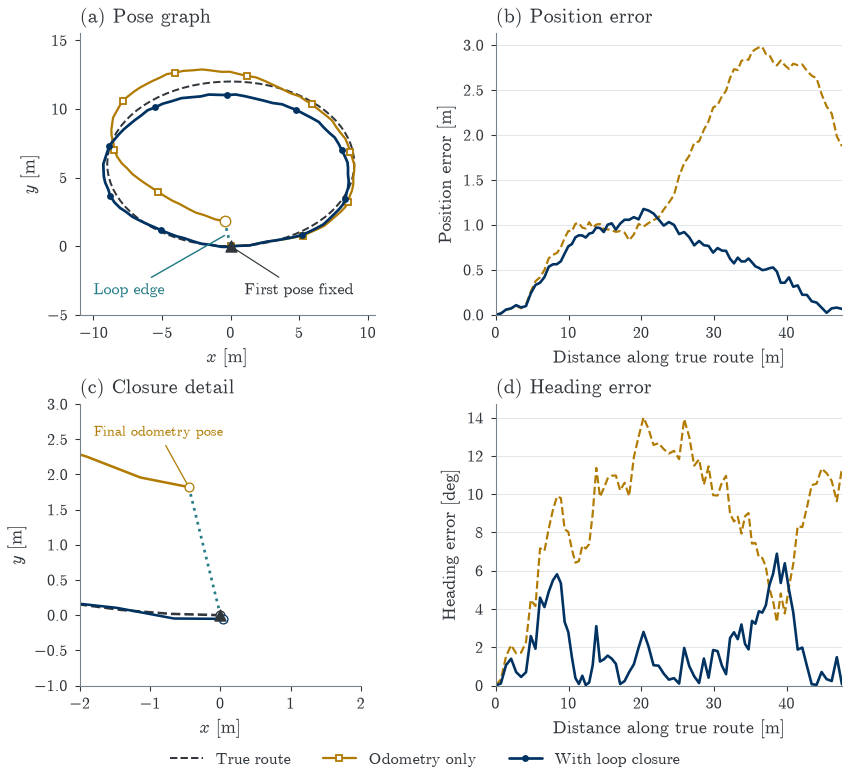

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(6.5, 6.0), layout='constrained')
ax_map, ax_position = axes[0]
ax_detail, ax_heading = axes[1]

ax_map.plot(truth[:, 0], truth[:, 1], color=INK, linestyle='--', linewidth=1.1,
            label='True route')
ax_map.plot(dead_reckoning[:, 0], dead_reckoning[:, 1], color=GOLD, linewidth=1.25,
            marker='s', markersize=2.8, markevery=8, markerfacecolor='white',
            label='Odometry only')
ax_map.plot(optimized[:, 0], optimized[:, 1], color=BLUE, linewidth=1.5,
            marker='o', markersize=2.8, markevery=8, label='With loop closure')
ax_map.plot([dead_reckoning[-1, 0], anchor[0]],
            [dead_reckoning[-1, 1], anchor[1]],
            color=TEAL, linestyle=':', linewidth=1.5)
ax_map.scatter(*anchor[:2], marker='^', s=38, color=INK, zorder=5)
ax_map.scatter(*dead_reckoning[-1, :2], s=34, edgecolor=GOLD, facecolor='white', zorder=5)
ax_map.annotate('First pose fixed', xy=anchor[:2], xytext=(1.0, -3.5),
                fontsize=9, color=INK,
                arrowprops={'arrowstyle': '-', 'color': INK, 'lw': 0.65})
loop_midpoint = 0.5 * (dead_reckoning[-1, :2] + anchor[:2])
ax_map.annotate('Loop edge', xy=loop_midpoint, xytext=(-10, -3.5),
                fontsize=9, color=TEAL,
                arrowprops={'arrowstyle': '-', 'color': TEAL, 'lw': 0.8})
ax_map.set(xlabel='$x$ [m]', ylabel='$y$ [m]', aspect='equal')
ax_map.set_anchor('W')
ax_map.set_xlim(-11.0, 10.5)
ax_map.set_ylim(-5.0, 15.5)
ax_map.set_title('(a) Pose graph', loc='left')
# A local view shows the endpoint mismatch that is compressed in the full map.
for poses, color, linestyle in [(truth, INK, '--'), (dead_reckoning, GOLD, '-'),
                                 (optimized, BLUE, '-')]:
    ax_detail.plot(poses[-6:, 0], poses[-6:, 1], color=color, linestyle=linestyle)
    ax_detail.scatter(*poses[-1, :2], s=24, facecolor='white', edgecolor=color, zorder=4)
ax_detail.scatter(*anchor[:2], marker='^', s=38, color=INK, zorder=5)
ax_detail.plot([dead_reckoning[-1, 0], anchor[0]],
               [dead_reckoning[-1, 1], anchor[1]], color=TEAL, linestyle=':', linewidth=1.5)
ax_detail.set(xlim=(-2, 2), ylim=(-1, 3), xlabel='$x$ [m]', ylabel='$y$ [m]',
              aspect='equal')
ax_detail.set_anchor('W')
ax_detail.set_title('(c) Closure detail', loc='left')
ax_detail.annotate('Final odometry pose', xy=dead_reckoning[-1, :2], xytext=(-1.8, 2.55),
                   fontsize=8, color=GOLD,
                   arrowprops={'arrowstyle': '-', 'color': GOLD, 'lw': .7})

for ax, before, after, title, ylabel in [
    (ax_position, position_error_before, position_error_after,
     '(b) Position error', 'Position error [m]'),
    (ax_heading, heading_error_before, heading_error_after,
     '(d) Heading error', 'Heading error [deg]'),
]:
    ax.plot(distance, before, color=GOLD, linestyle='--', linewidth=1.2)
    ax.plot(distance, after, color=BLUE, linewidth=1.45)
    ax.set(xlim=(0, distance[-1]), ylim=(0, None), ylabel=ylabel,
           xlabel='Distance along true route [m]')
    ax.set_title(title, loc='left')
    ax.grid(axis='y')
fig.legend(*ax_map.get_legend_handles_labels(), loc='outside lower center',
           ncol=3, fontsize=9)
fig.savefig(figure_dir / 'slam-loop-closure.pdf',
            metadata={'CreationDate': None, 'ModDate': None})
fig.savefig(figure_dir / 'slam-loop-closure.png', dpi=200)
plt.show()


### Interpretation and limits

The loop observation constrains relative translation and heading between the final and initial poses. Because heading errors rotate subsequent translations, correcting orientation also changes the route's shape. The first-pose gauge remains fixed throughout.

The figure reports estimation error, not posterior uncertainty. Computing confidence regions would require additional assumptions and a covariance calculation that respects the anchored gauge and the local linearization. No uncertainty bands are inferred from the appearance of the path.

The correspondence is known and every factor is treated as an inlier. A false loop closure could deform an otherwise plausible map. Real SLAM also requires front-end association, checks for inconsistent closures, and a noise model appropriate to the actual sensors.